# Introduction to Exploratory Data Analysis (EDA)

This notebook introduces the concept of exploratory data analysis (EDA), its objectives, and the systematic classification of EDA methods. It demonstrates why graphical analysis is essential alongside summary statistics.

**This Jupyter notebook does the following:**
- Defines EDA and its objectives
- Explains the systematics of EDA methods (univariate/multivariate, graphical/non-graphical)
- Demonstrates Anscombe's Quartet: four datasets with identical statistics but different patterns
- Plots the Datasaurus Dozen to reinforce why visualization matters
- Performs basic data quality checks (shape, data types, missing values, duplicates)


**"Exploratory data analysis (EDA) is a critical first step in analyzing the data [...]. Loosely speaking, any method of looking at data that does not include formal statistical modeling and inference falls under the term exploratory data analysis."**  
— Seltman, H.J. (2018). Experimental Design and Analysis, Chapter 4. (Term goes back to Tukey, J.W., 1977.)

## Objectives of EDA
- Enable unexpected discoveries in the data
- Suggest hypotheses about the causes of observed phenomena
- Assess assumptions on which statistical inference will be based
- Support the selection of appropriate statistical tools and techniques
- Check data quality (missing values, duplicates, implausible values) before any modeling

## Systematics of EDA Methods

| | Non-Graphical | Graphical |
|---|---|---|
| **Univariate** | mean, median, std, skewness | histogram, box plot, bar chart |
| **Multivariate** | correlation, covariance | scatter plot, scatter matrix, heatmap |

In [1]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

# Seaborn theme
import seaborn as sns
sns.set_theme(style='whitegrid')

## Anscombe's Quartet

Anscombe's quartet consists of **four datasets** that have nearly identical simple statistical properties (mean, variance, correlation, regression line) yet look very different when plotted. This demonstrates the importance of always visualizing your data.

**Key message:** Summary statistics alone can be misleading — always complement non-graphical with graphical EDA methods.

In [2]:
# Anscombe's quartet data
anscombe = sns.load_dataset('anscombe')
print('Summary statistics per dataset:')
anscombe.groupby('dataset').agg(
    x_mean=('x', 'mean'),
    y_mean=('y', 'mean'),
    x_var=('x', 'var'),
    y_var=('y', 'var'),
    corr=('x', lambda x: x.corr(anscombe.loc[x.index, 'y']))
).round(2)

Summary statistics per dataset:


,x_mean,y_mean,x_var,y_var,corr
dataset,,,,,
I,9.0,7.5,11.0,4.13,0.82
II,9.0,7.5,11.0,4.13,0.82
III,9.0,7.5,11.0,4.12,0.82
IV,9.0,7.5,11.0,4.12,0.82


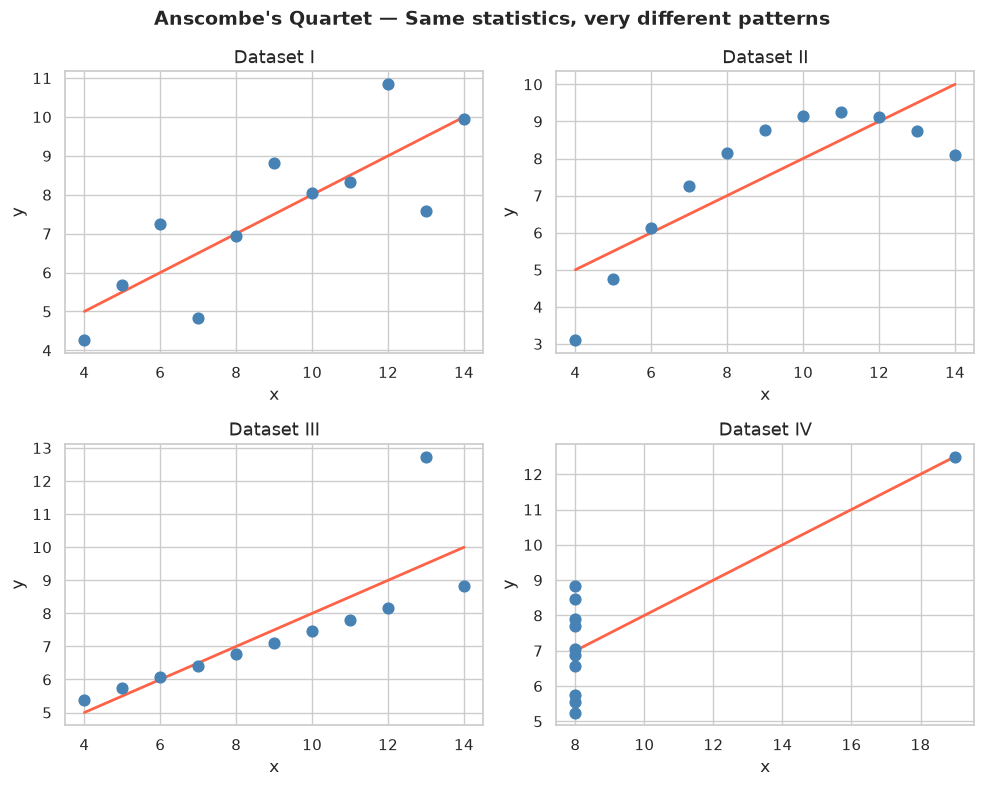

In [3]:
# Plot all four datasets
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=False, sharey=False)
axes = axes.flatten()

for i, (dataset, group) in enumerate(anscombe.groupby('dataset')):
    ax = axes[i]
    ax.scatter(group['x'], group['y'], color='steelblue', s=60, zorder=3)
    # Regression line
    m, b = np.polyfit(group['x'], group['y'], 1)
    x_line = np.linspace(group['x'].min(), group['x'].max(), 100)
    ax.plot(x_line, m * x_line + b, color='tomato', linewidth=2)
    ax.set_title(f'Dataset {dataset}', fontsize=13)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

fig.suptitle("Anscombe's Quartet — Same statistics, very different patterns", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## The Datasaurus Dozen

A modern variant of Anscombe's quartet (Matejka & Fitzmaurice, 2017): 12 datasets with identical summary statistics but wildly different shapes — including a dinosaur!

Datasaurus Dozen: 13 datasets
Summary statistics (all nearly identical):
              x             y       
           mean    std   mean    std
dataset                             
away      54.27  16.77  47.83  26.94
bullseye  54.27  16.77  47.83  26.94
circle    54.27  16.76  47.84  26.93
dino      54.26  16.77  47.83  26.94
dots      54.26  16.77  47.84  26.93


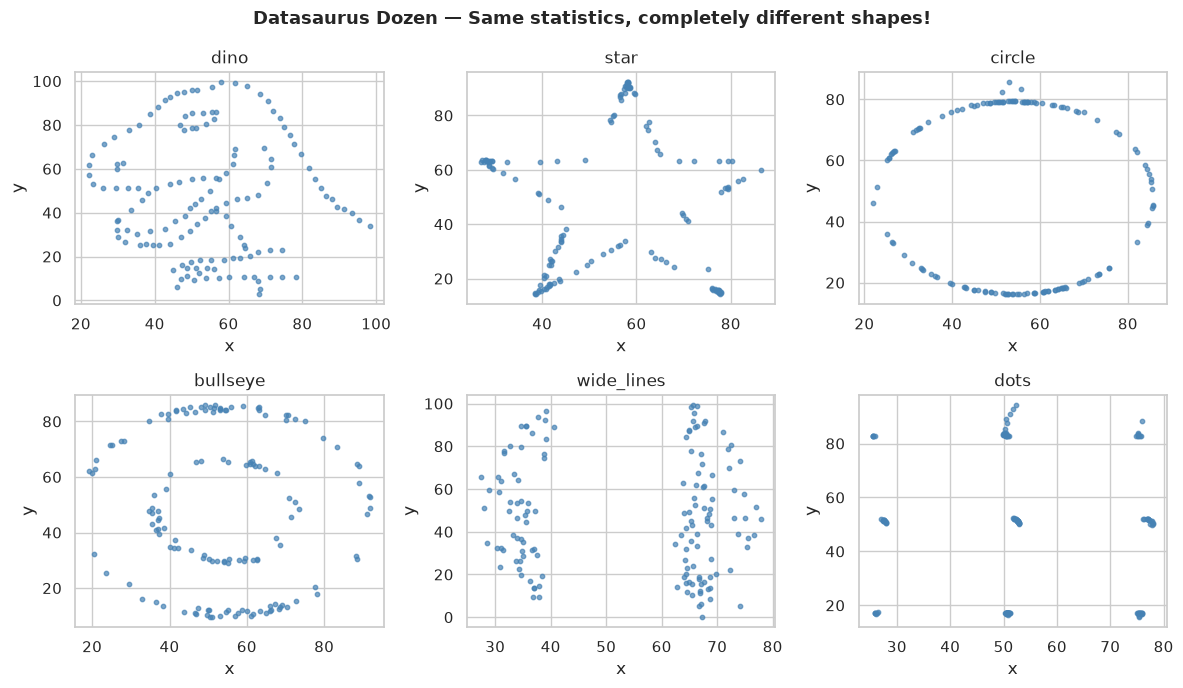

Source: https://www.research.autodesk.com/publications/same-stats-different-graphs/


In [4]:
import urllib.request, io
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-10-13/datasaurus.csv'
ds = pd.read_csv(url)
datasets = ds['dataset'].unique()
print(f'Datasaurus Dozen: {len(datasets)} datasets')
print('Summary statistics (all nearly identical):')
print(ds.groupby('dataset')[['x','y']].agg(['mean','std']).round(2).head(5))

# Plot a selection of datasets
selected = ['dino', 'star', 'circle', 'bullseye', 'wide_lines', 'dots']
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, name in zip(axes.flatten(), selected):
    subset = ds[ds['dataset'] == name]
    ax.scatter(subset['x'], subset['y'], s=10, alpha=0.7, color='steelblue')
    ax.set_title(name)
    ax.set_xlabel('x'); ax.set_ylabel('y')
fig.suptitle('Datasaurus Dozen — Same statistics, completely different shapes!', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('Source: https://www.research.autodesk.com/publications/same-stats-different-graphs/')

## Data Quality Checks

Before any analysis, always inspect the data for quality issues.

In [6]:
# Load apartment data
df = pd.read_csv('../apartments_data_enriched_cleaned.csv', )
print('Shape:', df.shape)
print()
df.head(3)

Shape: (774, 17)



,Unnamed: 0,web-scraper-order,address_raw,lat,lon,bfs_number,bfs_name,rooms,area,luxurious,price,price_per_m2,pop,pop_dens,emp,frg_pct,mean_taxable_income
0,0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",47.252171,8.845797,118,Rüti (ZH),3.0,49.0,0,1441.0,29.41,12286,1221.272366,5053.0,24.841283,65362.042683
1,1,1693998233-172,"Widacherstrasse 5, 8630 Rüti ZH, ZH",47.252087,8.854919,118,Rüti (ZH),3.0,111.0,0,2600.0,23.42,12286,1221.272366,5053.0,24.841283,65362.042683
2,2,1693998256-331,"Widenweg 14, 8630 Rüti ZH, ZH",47.253670,8.853993,118,Rüti (ZH),3.0,58.0,0,1490.0,25.69,12286,1221.272366,5053.0,24.841283,65362.042683


In [ ]:
# Data types
print('Data types:')
print(df.dtypes)
print()
# Missing values
print('Missing values per column:')
print(df.isnull().sum())
print()
# Duplicates
print(f'Duplicate rows: {df.duplicated().sum()}')

## Jupyter notebook --footer info--
(please always provide this at the end of each notebook)

In [ ]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('------------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('------------------------------------')